<a href="https://colab.research.google.com/github/rustam4ike/football_analytics/blob/main/%22%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B0%D1%8F_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_%E2%84%961_(%D0%A2%D1%80%D0%B5%D1%82%D1%8C%D0%B5_%D0%B7%D0%B0%D0%B4%D0%B0%D0%BD%D0%B8%D0%B5)%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## АНАЛИЗ И ПРОГНОЗИРОВАНИЕ ПОКАЗАТЕЛЕЙ ФУТБОЛЬНОГО КЛУБА

КРАТКАЯ ИНФОРМАЦИЯ:

В данной задачи выдуманный датасет "football_dataset.csv" несуществующего клуба, который содержит следующие данные:

Date: Дата матча в формате ДД-ММ-ГГГГ.

Place: Место проведения матча ("Home" означает домашний матч, "Away" — выездной).

Revenue ($k): Доход от матча в тысячах долларов.

Expenses ($k): Расходы на проведение матча в тысячах долларов.

Net Profit ($k): Чистая прибыль от матча, в тысячах долларов.

Attendance: Количество зрителей на матче.

Match Result: Результат матча ("Victory" — победа, "Draw" — ничья, "Defeat" — поражение).

Tournament Position: Текущая позиция команды в турнирной таблице после каждого матча.


Две поставленные задачи:

АНАЛИЗ:
1.   Соотношение чистой прибыли домашних и гостевых матчей
2.   Соотношение положения турнирной таблицы и чистой прибыли
3.   Соотношение побед в домашних и гостевых матчей

ПРОГНОЗИРОВАНИЕ чистой прибыли

АНАЛИЗ:

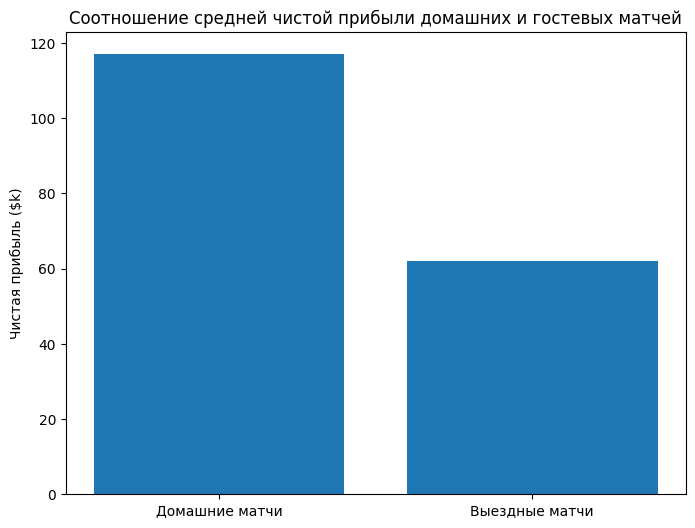

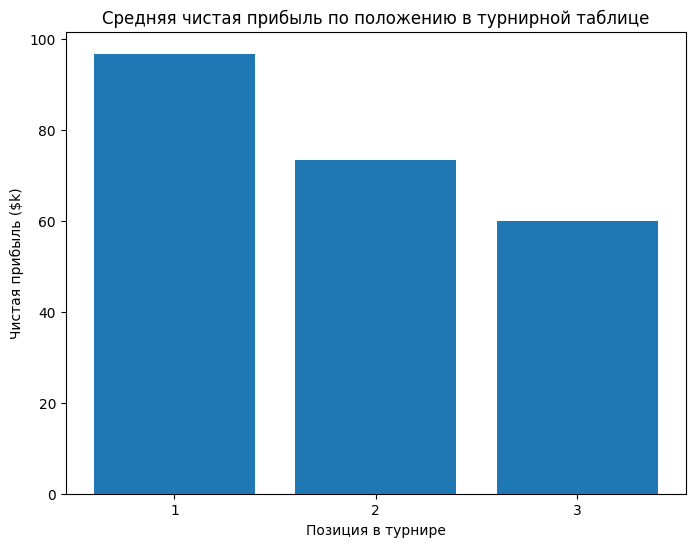

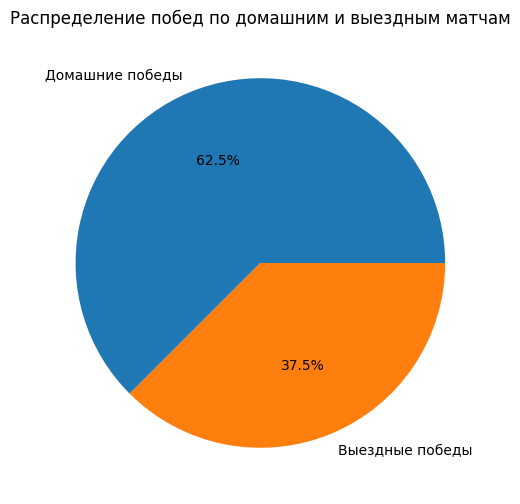

In [ ]:
import pandas as pd
from matplotlib import pyplot as plt


def load_data():
    """Функция загрузки данных"""
    df = pd.read_csv('football_dataset.csv')

    return df

# Анализ №1:
def analyze_net_profit_by_place(df):
    """Функция расчета прибыли к домашним и гостевым матчам"""

    # Среднее значение чистой прибыли домашних и гостевых матчей
    home_profit = df[df['Place'] == 'Home']['Net Profit ($k)'].mean()
    away_profit = df[df['Place'] == 'Away']['Net Profit ($k)'].mean()

    # Построение столбчатой диаграммы
    plt.figure(figsize=(8, 6))
    plt.bar(['Домашние матчи', 'Выездные матчи'], [home_profit, away_profit])
    plt.title('Соотношение средней чистой прибыли домашних и гостевых матчей')
    plt.ylabel('Чистая прибыль ($k)')
    plt.show()

# Анализ №2:
def analyze_net_profit_by_tournament_position(df):
    """Функция расчета прибыли от положения турнирной таблицы"""

    # Группировка по позициям турнира и расчет среднего значения чистой прибыли
    position_profit = df.groupby('Tournament Position')['Net Profit ($k)'].mean().sort_values(ascending=False)

    # Построение столбчатой диаграммы
    plt.figure(figsize=(8, 6))
    plt.bar(position_profit.index.astype(str), position_profit.values)
    plt.title('Средняя чистая прибыль по положению в турнирной таблице')
    plt.xlabel('Позиция в турнире')
    plt.ylabel('Чистая прибыль ($k)')
    plt.show()

# Анализ №3:
def analyze_match_results_by_place(df):
    """Расчет соотношения побед в домашних и гостевых матчах"""

    # Подсчет количества побед дома и на выезде
    home_victories = len(df[(df['Place'] == 'Home') & (df['Match Result'] == 'Victory')])
    away_victories = len(df[(df['Place'] == 'Away') & (df['Match Result'] == 'Victory')])

    # Построение круговой диаграммы
    plt.figure(figsize=(8, 6))
    plt.pie([home_victories, away_victories], labels=['Домашние победы', 'Выездные победы'], autopct='%1.1f%%')
    plt.title('Распределение побед по домашним и выездным матчам')
    plt.show()


# ОСНОВНАЯ ПРОГРАММА
df = load_data()
analyze_net_profit_by_place(df)
analyze_net_profit_by_tournament_position(df)
analyze_match_results_by_place(df)

ПРОГНОЗИРОВАНИЕ:

Точность модели (R²): 90.70%
[90.00141 60.00031 69.99984 60.00031]


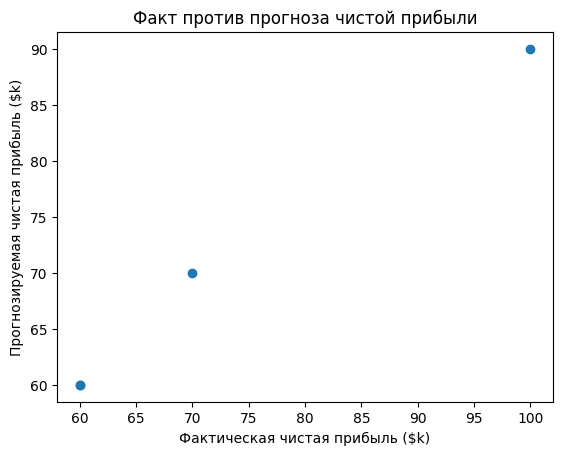

In [ ]:
import pandas as pd
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from matplotlib import pyplot as plt

def load_data():
    """Функция загрузки данных"""

    df = pd.read_csv('football_dataset.csv')

    return df

def preprocess_data(df):
    """Функция преобразования категориальных переменных в числовые"""

    # Создание копии
    df_encoded = df.copy()
    # Преобразование значений в числа
    df_encoded['Place'] = df_encoded['Place'].map({'Home': 1, 'Away': 0})
    df_encoded['Match Result'] = df_encoded['Match Result'].map({'Victory': 1, 'Draw': 0, 'Defeat': -1})

    return df_encoded

def create_and_train_model(X_train, y_train):
    """Функция создания модели и обучение"""

    # Модель градиентного бустинга
    model = XGBRegressor(objective='reg:squarederror', random_state=42)
    # Обучение модели на тренировочных данных
    model.fit(X_train, y_train)

    return model

def predict_and_evaluate(model, X_test, y_test):
    """Функция прогнозирования и оценка точности"""

    # Предсказанные значения на тестовых данных
    predictions = model.predict(X_test)

    # R² показывает, какую долю дисперсии объясняет модель
    r2 = r2_score(y_test, predictions)
    print(f"Точность модели (R²): {r2:.2%}")
    # Интерпретация:
    # 100% - идеальное предсказание
    # 0% - модель не лучше среднего значения
    # Отрицательные значения - модель очень плохая

    return predictions

def visualize_result():
    """Функция визуализации"""

    plt.scatter(y_test, predictions)
    plt.xlabel('Фактическая чистая прибыль ($k)')
    plt.ylabel('Прогнозируемая чистая прибыль ($k)')
    plt.title('Факт против прогноза чистой прибыли')
    plt.show()


# ОСНОВНАЯ ПРОГРАММА
df = load_data()
df_encoded = preprocess_data(df)

# Выбор признаков и целевой переменной
features = features = ['Place', 'Attendance', 'Match Result', 'Tournament Position']
target = 'Net Profit ($k)'

X = df_encoded[features]
y = df_encoded[target]

# Разделение на тренировочную и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Обучение модели
model = create_and_train_model(X_train, y_train)

# Оценка качества модели
predictions = predict_and_evaluate(model, X_test, y_test)
print(predictions)

# Отображение графика
visualize_result()